# 1. Problema e pergunta analítica

**Contexto:** O Nordeste concentra boa parte da geração eólica e solar do país.
Quando gera mais do que consome, o excedente é exportado para outras regiões.

**Público:** Planejamento do setor elétrico (ONS, EPE) e transmissão.

**Decisão apoiada:** Identificar os períodos de maior exportação para orientar
reforços de transmissão.

**Pergunta:** Como a geração eólica e solar do Nordeste se relaciona com a
energia exportada pelo subsistema entre 2023 e 2025, e em quais meses e horários
a exportação é maior?

**Hipótese:** A exportação aumenta quando a geração eólica é maior.

**Critérios de sucesso:**
- Medir a relação entre geração renovável e exportação.
- Identificar os meses e horários de pico.
- Comparar os três anos.

### 1.1 Verificação dos arquivos

* Entender quais informações estão disponíveis nas bases de dados.
* Conferir se os três arquivos anuais têm a mesma estrutura: mesmas colunas, na mesma ordem, e período coerente com o ano do arquivo.

In [29]:
import pandas as pd
from pathlib import Path

dados_brutos_pasta = Path("dados")
dados_uniao_pasta = Path("resultados")

for arquivo in sorted(dados_brutos_pasta.glob("*.csv")):
    df_temp = pd.read_csv(arquivo, sep=";")
    print(arquivo.name)
    display(df_temp.head())
    df_temp.info()
    print()

BALANCO_ENERGIA_SUBSISTEMA_2023.csv


,id_subsistema,nom_subsistema,din_instante,val_gerhidraulica,val_gertermica,val_gereolica,val_gersolar,val_carga,val_intercambio
0,NE,NORDESTE,2023-01-01 00:00:00,3874.072998,677.062988,13305.261719,1.932,10455.818,7402.512
1,N,NORTE,2023-01-01 00:00:00,7858.744141,877.854980,211.772003,0.000,5990.553,2957.818
2,SIN,SISTEMA INTERLIGADO NACIONAL,2023-01-01 00:00:00,39057.309000,5698.335000,14138.750000,21.155,58904.080,11.470
3,SE,SUDESTE/CENTRO-OESTE,2023-01-01 00:00:00,24661.111328,4071.576904,6.000000,18.223,32183.885,-3426.974
4,S,SUL,2023-01-01 00:00:00,2663.381104,71.839996,615.716003,1.000,10273.827,-6921.890


<class 'pandas.DataFrame'>
RangeIndex: 43800 entries, 0 to 43799
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id_subsistema      43800 non-null  str    
 1   nom_subsistema     43800 non-null  str    
 2   din_instante       43800 non-null  str    
 3   val_gerhidraulica  43800 non-null  float64
 4   val_gertermica     43800 non-null  float64
 5   val_gereolica      43800 non-null  float64
 6   val_gersolar       43800 non-null  float64
 7   val_carga          43800 non-null  float64
 8   val_intercambio    43800 non-null  float64
dtypes: float64(6), str(3)
memory usage: 3.0 MB

BALANCO_ENERGIA_SUBSISTEMA_2024.csv


,id_subsistema,nom_subsistema,din_instante,val_gerhidraulica,val_gertermica,val_gereolica,val_gersolar,val_carga,val_intercambio
0,NE,NORDESTE,2024-01-01 00:00:00,3503.617920,486.473999,2491.562988,1.550,11976.884,-5493.679
1,N,NORTE,2024-01-01 00:00:00,3006.385010,2469.684082,2.193000,0.000,6539.560,-1061.298
2,SIN,SISTEMA INTERLIGADO NACIONAL,2024-01-01 00:00:00,51266.264000,8982.283000,3205.270000,11.213,63465.030,0.000
3,SE,SUDESTE/CENTRO-OESTE,2024-01-01 00:00:00,31710.361328,5046.854980,8.500000,8.663,34981.614,1792.766
4,S,SUL,2024-01-01 00:00:00,13045.899414,979.270020,703.013977,1.000,9966.972,4762.211


<class 'pandas.DataFrame'>
RangeIndex: 43920 entries, 0 to 43919
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id_subsistema      43920 non-null  str    
 1   nom_subsistema     43920 non-null  str    
 2   din_instante       43920 non-null  str    
 3   val_gerhidraulica  43920 non-null  float64
 4   val_gertermica     43920 non-null  float64
 5   val_gereolica      43920 non-null  float64
 6   val_gersolar       43920 non-null  float64
 7   val_carga          43920 non-null  float64
 8   val_intercambio    43920 non-null  float64
dtypes: float64(6), str(3)
memory usage: 3.0 MB

BALANCO_ENERGIA_SUBSISTEMA_2025.csv


,id_subsistema,nom_subsistema,din_instante,val_gerhidraulica,val_gertermica,val_gereolica,val_gersolar,val_carga,val_intercambio
0,NE,NORDESTE,2025-01-01 00:00:00,2219.280,415.154,16070.653,0.0,12251.182,6453.905
1,N,NORTE,2025-01-01 00:00:00,6818.532,1576.087,401.685,0.0,7097.751,1698.553
2,SIN,SISTEMA INTERLIGADO NACIONAL,2025-01-01 00:00:00,40778.712,6835.338,17662.519,1.0,65277.570,0.000
3,SE,SUDESTE/CENTRO-OESTE,2025-01-01 00:00:00,23801.970,4510.835,5.001,0.0,35374.033,-7056.227
4,S,SUL,2025-01-01 00:00:00,7938.930,333.262,1185.180,1.0,10554.603,-1096.231


<class 'pandas.DataFrame'>
RangeIndex: 43800 entries, 0 to 43799
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id_subsistema      43800 non-null  str    
 1   nom_subsistema     43800 non-null  str    
 2   din_instante       43800 non-null  str    
 3   val_gerhidraulica  43800 non-null  float64
 4   val_gertermica     43800 non-null  float64
 5   val_gereolica      43800 non-null  float64
 6   val_gersolar       43800 non-null  float64
 7   val_carga          43800 non-null  float64
 8   val_intercambio    43800 non-null  float64
dtypes: float64(6), str(3)
memory usage: 3.0 MB



#### Diagnóstico
* Cada linha representa **uma hora em um subsistema**.
* São 5 subsistemas: Norte, Nordeste, Sudeste/Centro-Oeste, Sul e o SIN (Sistema Interligado Nacional, que é a soma dos outros quatro).
* Todos os arquivos têm o mesmo número de colunas e os mesmos tipos de dados, então posso juntá-los em uma base única.
* A coluna `val_intercambio` mostra a troca de energia do subsistema com os demais. Nesta análise, considero valores positivos como exportação e negativos como importação (convenção a confirmar no dicionário de dados do ONS).

## 1.2 Extração e consolidação dos dados

Os dados brutos do ONS estão divididos em três arquivos anuais (2023, 2024 e 2025),
na pasta `dados brutos/`. Nesta etapa leio todos os CSVs da pasta, junto em uma
única base e salvo o resultado em `dados_união/BALANCO_ENERGIA_SUBSISTEMA_2023_a_2025.csv`.

Os arquivos originais não são alterados, então os dados brutos ficam preservados.

In [30]:

df_lista = {}

for i in dados_brutos_pasta.iterdir():
    if i.suffix == '.csv':
        df_lista[i.stem] = pd.read_csv(i)

data_frame_geral = pd.DataFrame()

for k, v in df_lista.items():
    data_frame_geral = pd.concat([data_frame_geral, v], ignore_index=True)

data_frame_geral.to_csv(dados_uniao_pasta / "BALANCO_ENERGIA_SUBSISTEMA_2023_a_2025.csv", index=False)

## 2. Revisão e limpeza dos dados

Nesta etapa reviso a base consolidada para encontrar valores nulos, duplicados ou qualquer outra inconsistência.

In [31]:
df_geral = pd.read_csv(dados_uniao_pasta / "BALANCO_ENERGIA_SUBSISTEMA_2023_a_2025.csv", sep=";")

### Valores nulos
Nenhum valor nulo encontrado.

In [32]:
df_geral.isnull().sum()

id_subsistema        0
nom_subsistema       0
din_instante         0
val_gerhidraulica    0
val_gertermica       0
val_gereolica        0
val_gersolar         0
val_carga            0
val_intercambio      0
dtype: int64

### Valores duplicados
Nenhuma linha duplicada encontrada.

In [33]:
df_geral.duplicated().sum()

np.int64(0)

### Conversão da data
A coluna `din_instante` vem como texto. Converto para data e, a partir dela, crio as colunas de ano, mês e hora que vou usar nos gráficos.

In [34]:
df_geral["din_instante"] = pd.to_datetime(df_geral["din_instante"], format="%Y-%m-%d %H:%M:%S")
df_geral["ano"] = df_geral["din_instante"].dt.year
df_geral["mes"] = df_geral["din_instante"].dt.month
df_geral["hora"] = df_geral["din_instante"].dt.hour

In [35]:
df_geral.info()

<class 'pandas.DataFrame'>
RangeIndex: 131520 entries, 0 to 131519
Data columns (total 12 columns):
 #   Column             Non-Null Count   Dtype         
---  ------             --------------   -----         
 0   id_subsistema      131520 non-null  str           
 1   nom_subsistema     131520 non-null  str           
 2   din_instante       131520 non-null  datetime64[us]
 3   val_gerhidraulica  131520 non-null  float64       
 4   val_gertermica     131520 non-null  float64       
 5   val_gereolica      131520 non-null  float64       
 6   val_gersolar       131520 non-null  float64       
 7   val_carga          131520 non-null  float64       
 8   val_intercambio    131520 non-null  float64       
 9   ano                131520 non-null  int32         
 10  mes                131520 non-null  int32         
 11  hora               131520 non-null  int32         
dtypes: datetime64[us](1), float64(6), int32(3), str(2)
memory usage: 10.5 MB


## 3. Análise exploratória

### 3.1 Comparação entre subsistemas

Antes de focar no Nordeste, comparo a geração solar e eólica entre as regiões para confirmar o peso da região no país. O SIN fica de fora porque é a soma das outras.

In [36]:
import seaborn as sns
import matplotlib.pyplot as plt

In [37]:
df_regioes = df_geral[df_geral["id_subsistema"] != "SIN"]

medias = df_regioes.groupby(["ano", "nom_subsistema"])[["val_gersolar", "val_gereolica"]].mean()
medias["part_solar_%"] = medias["val_gersolar"] / medias.groupby("ano")["val_gersolar"].transform("sum") * 100
medias["part_eolica_%"] = medias["val_gereolica"] / medias.groupby("ano")["val_gereolica"].transform("sum") * 100
medias.round(1)

val_gersolar  val_gereolica  part_solar_%  \
ano  nom_subsistema                                                    
2023 NORDESTE                    1821.4        10009.1          37.1   
     NORTE                        208.0          210.0           4.2   
     SUDESTE/CENTRO-OESTE        2319.5            6.9          47.2   
     SUL                          560.9          661.9          11.4   
2024 NORDESTE                    2820.6        11300.5          33.8   
     NORTE                        421.8          203.8           5.1   
     SUDESTE/CENTRO-OESTE        4033.1            6.2          48.3   
     SUL                         1074.2          727.5          12.9   
2025 NORDESTE                    3341.2        12189.4          31.9   
     NORTE                        583.5          212.4           5.6   
     SUDESTE/CENTRO-OESTE        5257.4           68.7          50.2   
     SUL                         1301.0          698.8          12.4   

                           part_eolica_%  
ano  nom_subsistema                       
2023 NORDESTE                       91.9  
     NORTE                           1.9  
     SUDESTE/CENTRO-OESTE            0.1  
     SUL                             6.1  
2024 NORDESTE                       92.3  
     NORTE                           1.7  
     SUDESTE/CENTRO-OESTE            0.1  
     SUL                             5.9  
2025 NORDESTE                       92.6  
     NORTE                           1.6  
     SUDESTE/CENTRO-OESTE            0.5  
     SUL                             5.3

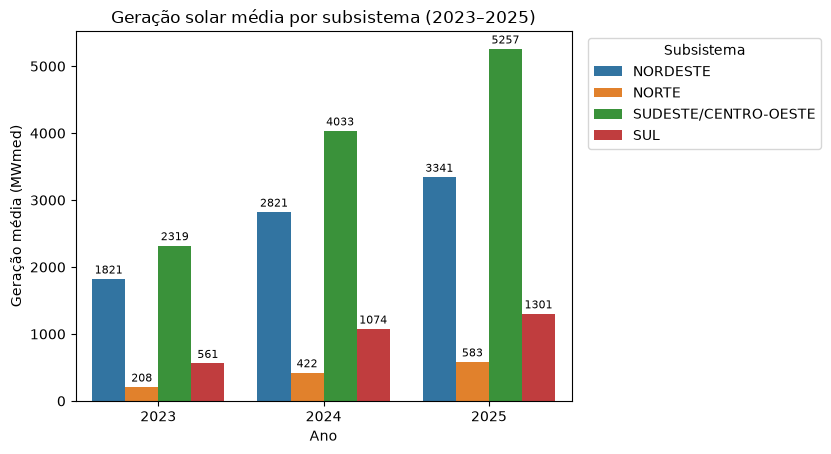

In [38]:
ax = sns.barplot(data=df_regioes, x="ano", y="val_gersolar",
                 hue="nom_subsistema", palette="tab10", errorbar=None)

for barras in ax.containers:
    ax.bar_label(barras, fmt="%.0f", fontsize=8, padding=2)

ax.set_title("Geração solar média por subsistema (2023–2025)")
ax.set_ylabel("Geração média (MWmed)")
ax.set_xlabel("Ano")
ax.legend(title="Subsistema", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.show()

**Observação:** a geração solar cresceu em todas as regiões entre 2023 e 2025.
No Nordeste, a média subiu 83% (1.821 → 3.341 MWmed), mas o Sudeste/Centro-Oeste
cresceu mais rápido (+127%) e hoje é a região com maior geração solar. Com isso,
a participação do Nordeste na solar nacional caiu de 37% para 32%.

No Nordeste, a solar ainda é bem menor que a eólica (3.341 contra 12.189 MWmed
em 2025), o que indica que a exportação da região depende principalmente do vento.

*Nota: os valores são médias horárias ao longo do ano, incluindo a noite,
quando a solar é zero.*

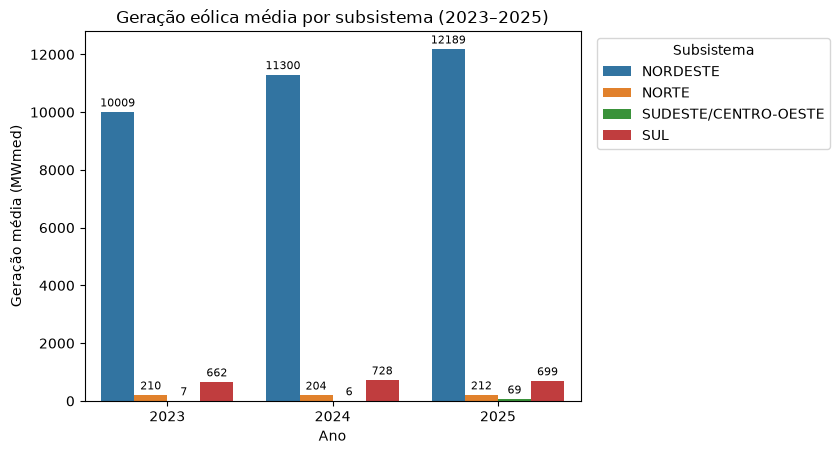

In [39]:
ax = sns.barplot(data=df_regioes, x="ano", y="val_gereolica",
                 hue="nom_subsistema", palette="tab10", errorbar=None)

for barras in ax.containers:
    ax.bar_label(barras, fmt="%.0f", fontsize=8, padding=2)

ax.set_title("Geração eólica média por subsistema (2023–2025)")
ax.set_ylabel("Geração média (MWmed)")
ax.set_xlabel("Ano")
ax.legend(title="Subsistema", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.show()

**Observação:** o Nordeste concentra praticamente toda a geração eólica do país
(cerca de 92%), com crescimento de 22% na média entre 2023 e 2025
(10.009 → 12.189 MWmed). As outras regiões têm participação pequena e estável.
Isso reforça o foco da análise no Nordeste.

### 3.2 Sazonalidade no Nordeste

As próximas analises seram feitas apenas sobre o nordeste

In [40]:
df_ne = df_geral[df_geral["id_subsistema"] == "NE"].copy()
df_ne["data_hora"] = df_ne["din_instante"]
df_ne["ano_mes"] = df_ne["data_hora"].dt.to_period("M").astype(str)

meses = ["Jan", "Fev", "Mar", "Abr", "Mai", "Jun",
         "Jul", "Ago", "Set", "Out", "Nov", "Dez"]

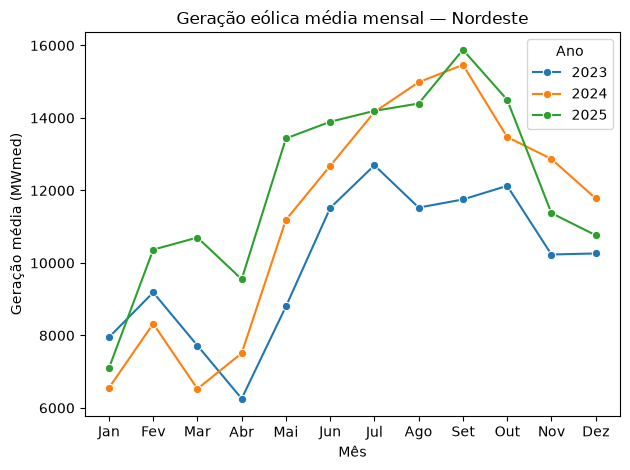

In [41]:
ax = sns.lineplot(data=df_ne, x="mes", y="val_gereolica",
                  hue="ano", palette="tab10", marker="o", errorbar=None)

ax.set_xticks(range(1, 13))
ax.set_xticklabels(meses)
ax.set_title("Geração eólica média mensal — Nordeste")
ax.set_ylabel("Geração média (MWmed)")
ax.set_xlabel("Mês")
ax.legend(title="Ano")
plt.tight_layout()
plt.show()

**Observação (eólica):** a geração eólica do Nordeste tem sazonalidade clara e
parecida nos três anos: baixa entre janeiro e abril e pico entre julho e
setembro (a "safra dos ventos"). Em 2025, a média de setembro foi mais que o dobro
da de janeiro. O crescimento entre os anos se concentra no segundo semestre.

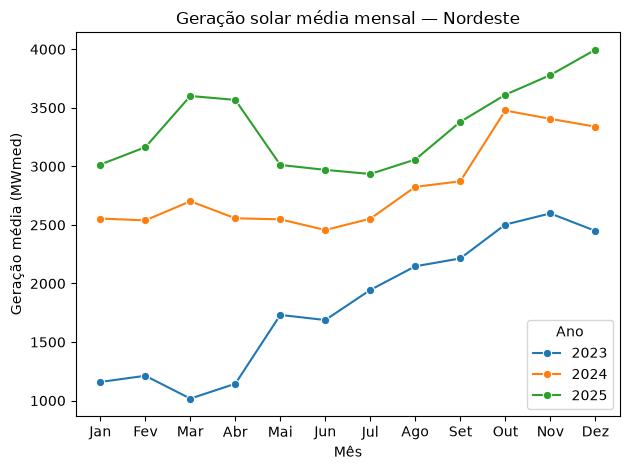

In [42]:
ax = sns.lineplot(data=df_ne, x="mes", y="val_gersolar",
                  hue="ano", palette="tab10", marker="o", errorbar=None)

ax.set_xticks(range(1, 13))
ax.set_xticklabels(meses)
ax.set_title("Geração solar média mensal — Nordeste")
ax.set_ylabel("Geração média (MWmed)")
ax.set_xlabel("Mês")
ax.legend(title="Ano")
plt.tight_layout()
plt.show()

**Observação (solar):** a curva mensal da solar reflete principalmente a entrada
de novas usinas ao longo do período, e não só o clima. Há uma leve
sazonalidade, com geração menor entre maio e julho e maior entre setembro e
dezembro. Como a base não informa a capacidade instalada, não dá para separar
totalmente os dois efeitos.

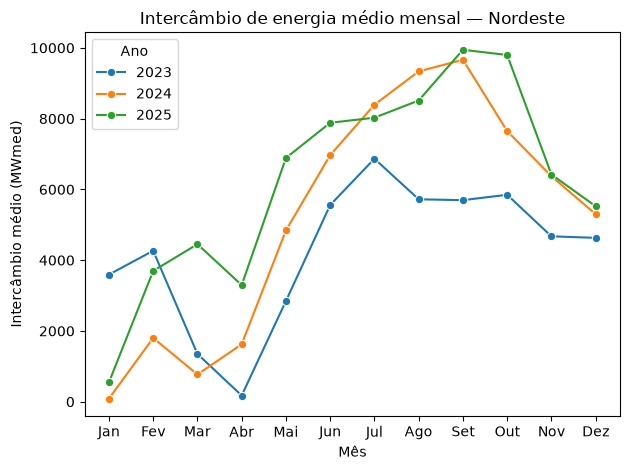

In [43]:
ax = sns.lineplot(data=df_ne, x="mes", y="val_intercambio",
                  hue="ano", palette="tab10", marker="o", errorbar=None)

ax.set_xticks(range(1, 13))
ax.set_xticklabels(meses)
ax.set_title("Intercâmbio de energia médio mensal — Nordeste")
ax.set_ylabel("Intercâmbio médio (MWmed)")
ax.set_xlabel("Mês")
ax.legend(title="Ano")
plt.tight_layout()
plt.show()

**Observação (intercâmbio):** o intercâmbio segue o mesmo desenho da eólica. Fica
mais baixo no começo do ano e sobe a partir de maio, com os maiores valores entre
setembro e outubro. O patamar do segundo semestre também aumenta de um ano para o outro.

### 3.3 Padrão por hora do dia

Após analisar de forma "geral", o objetivo será fazer uma análise mais detalhada usando as horas, para isso, usei heatmaps.
No intercâmbio, a escala de cor é centrada no zero: azul indica exportação e vermelho, importação.

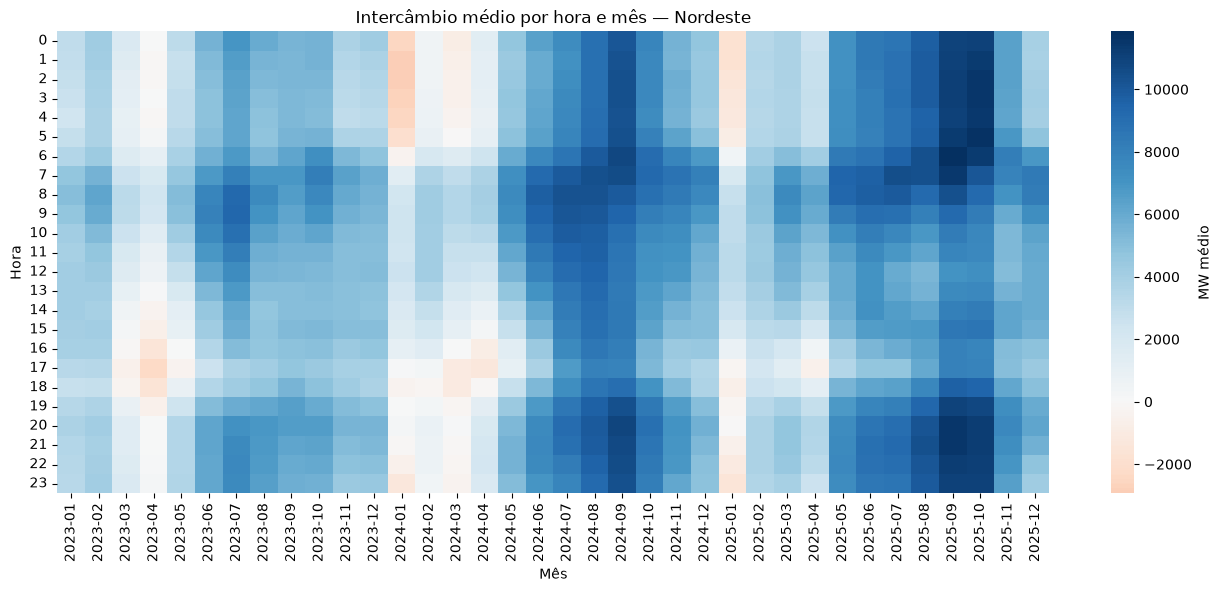

In [44]:
tabela_intercambio = df_ne.pivot_table(values="val_intercambio", index="hora",
                                       columns="ano_mes", aggfunc="mean")

plt.figure(figsize=(16, 6))
sns.heatmap(tabela_intercambio, cmap="RdBu", center=0, cbar_kws={"label": "MW médio"})
plt.yticks(rotation=0)
plt.title("Intercâmbio médio por hora e mês — Nordeste")
plt.xlabel("Mês"); plt.ylabel("Hora")
plt.show()

**Observação:** o Nordeste exporta mais entre maio e outubro, com pico em setembro e outubro,
e o volume exportado cresce a cada ano. No começo do ano o intercâmbio cai bastante e chega
a ficar negativo, ou seja, a região importa energia, principalmente no fim da tarde
(jan/2024, jan/2025 e mar–abr de 2023 e 2024).

Também muda o horário da exportação: em 2023 ela era maior pela manhã, enquanto em 2024 e 2025,
nos meses de pico, fica alta também à noite e de madrugada. O fim da tarde (16h–18h)
é o horário mais fraco em todos os anos.

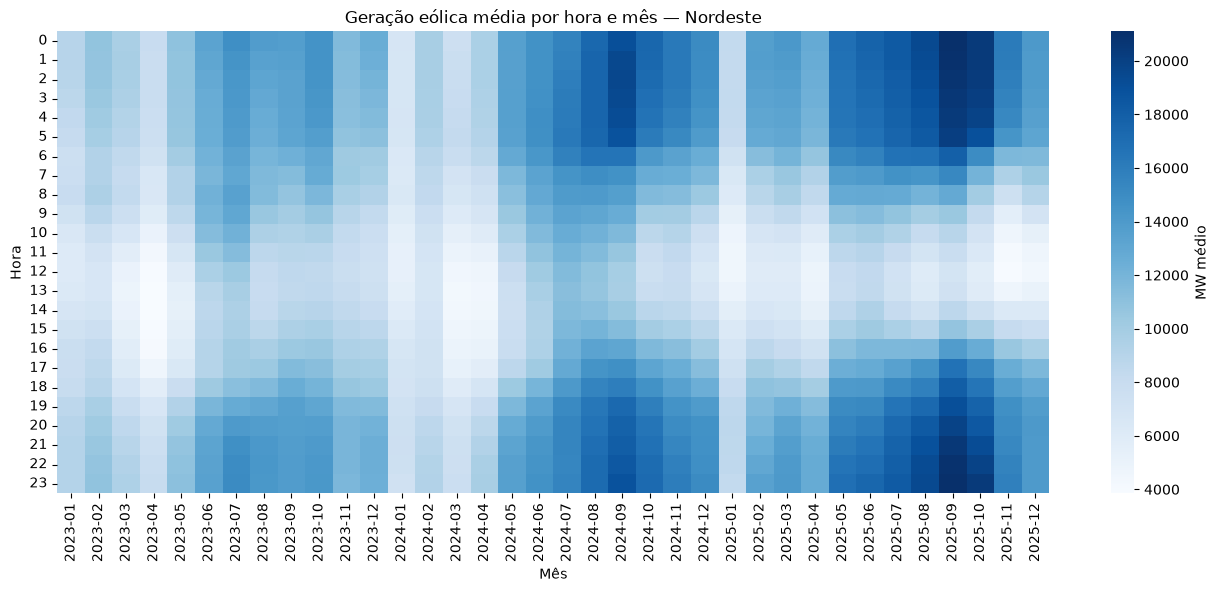

In [45]:
tabela_eolica = df_ne.pivot_table(values="val_gereolica", index="hora",
                                  columns="ano_mes", aggfunc="mean")

plt.figure(figsize=(16, 6))
sns.heatmap(tabela_eolica, cmap="Blues", cbar_kws={"label": "MW médio"})
plt.yticks(rotation=0)
plt.title("Geração eólica média por hora e mês — Nordeste")
plt.xlabel("Mês"); plt.ylabel("Hora")
plt.show()

**Observação:** a eólica é mais forte à noite e de madrugada (19h–5h) e mais fraca no meio do dia
(10h–14h). A sazonalidade é a mesma dos gráficos mensais, forte de junho a novembro e fraca de
janeiro a abril, e o pico cresce a cada ano, chegando a cerca de 20 mil MW em setembro e outubro de 2025.

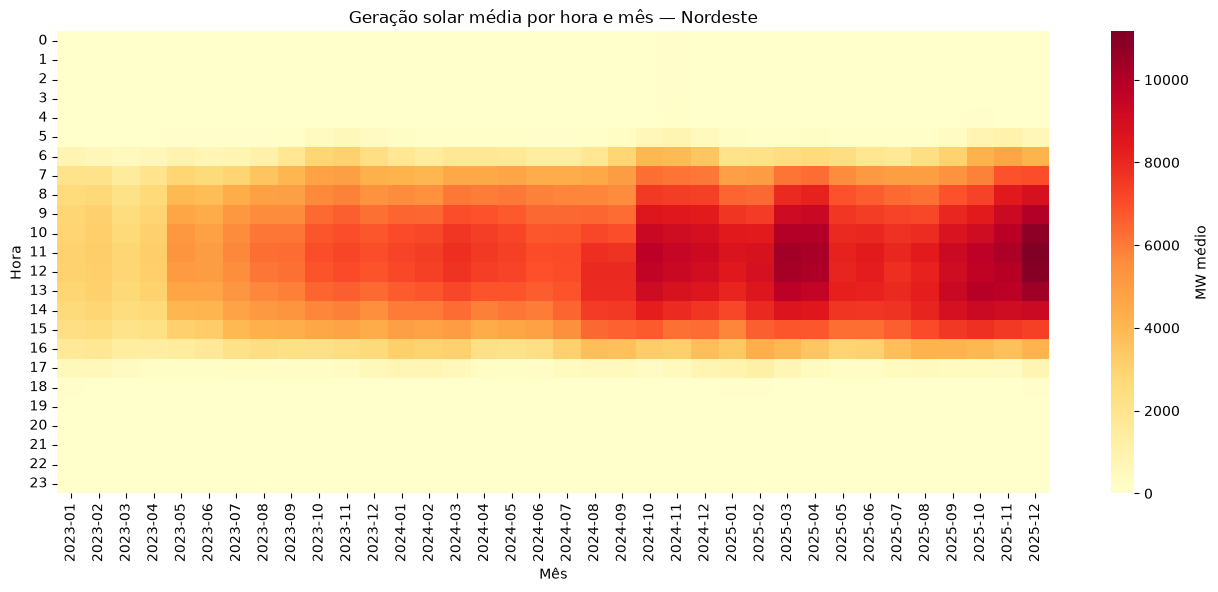

In [46]:
tabela_solar = df_ne.pivot_table(values="val_gersolar", index="hora",
                                 columns="ano_mes", aggfunc="mean")

plt.figure(figsize=(16, 6))
sns.heatmap(tabela_solar, cmap="YlOrRd", cbar_kws={"label": "MW médio"})
plt.yticks(rotation=0)
plt.title("Geração solar média por hora e mês — Nordeste")
plt.xlabel("Mês"); plt.ylabel("Hora")
plt.show()

**Observação:** a solar fica entre 6h e 17h, com pico entre 10h e 13h. O que mais chama atenção é o
crescimento: o pico passa de cerca de 4 mil MW em 2023 para mais de 10 mil MW no fim de 2025.
O salto em maio de 2023 provavelmente tem a ver com a entrada de novas usinas.

Comparando os três heatmaps, a sazonalidade do intercâmbio acompanha a da eólica, e a exportação
noturna que aparece em 2024 e 2025 coincide com o aumento da eólica nesses horários.

### 3.4 Relação entre geração e intercâmbio

Para medir a relação, calculo a correlação de cada fonte (e da carga) com o intercâmbio,
usando os dados horários, e depois comparo o perfil médio de cada uma ao longo do dia.

In [47]:
base = (df_ne.groupby("data_hora")[["val_gereolica", "val_gersolar", "val_intercambio", "val_carga"]]
             .sum())
base.columns = ["eolica", "solar", "intercambio", "carga"]

base.corr()["intercambio"].round(2)

eolica         0.78
solar          0.16
intercambio    1.00
carga         -0.02
Name: intercambio, dtype: float64

In [48]:
# Correlação com o intercâmbio em cada ano
corr_ano = (base.groupby(base.index.year).corr()
                .xs("intercambio", level=1)[["eolica", "solar", "carga"]])
corr_ano.round(2)

,eolica,solar,carga
data_hora,,,
2023,0.84,0.21,0.01
2024,0.81,0.18,-0.13
2025,0.70,0.05,-0.17


**Observação:** *(completar depois de rodar: a correlação com a eólica se mantém nos três anos?)*

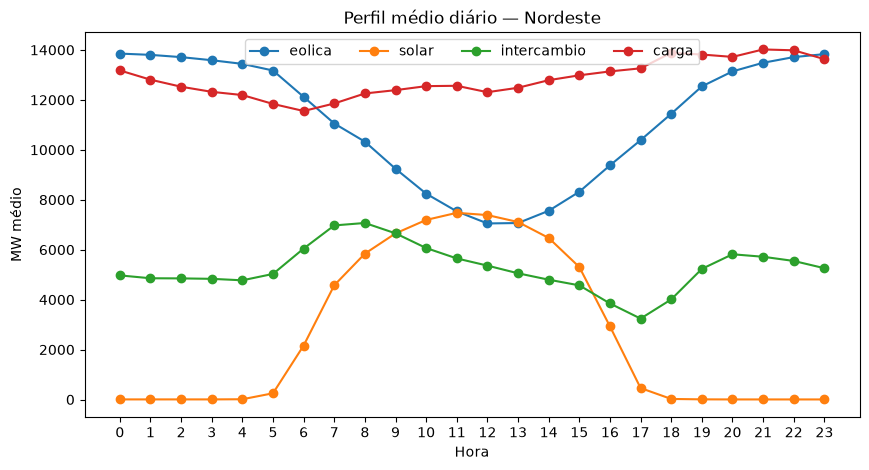

In [49]:
perfil = base.groupby(base.index.hour).mean()

ax = perfil.plot(figsize=(10, 5), marker="o")
ax.set_xticks(range(24))
ax.set_xlabel("Hora"); ax.set_ylabel("MW médio")
ax.set_title("Perfil médio diário — Nordeste")
ax.legend(loc="upper center", ncol=4)
plt.show()

**Observação:** a eólica tem correlação forte com o intercâmbio (0,78). A solar tem correlação
fraca (0,16), já que só gera durante o dia, e a carga praticamente não tem relação (−0,02).
Ou seja, o que define quanto o Nordeste exporta é a oferta de energia, principalmente do vento.

No perfil diário:
- **Madrugada (0h–5h):** a eólica está no máximo e sustenta a exportação.
- **Manhã (6h–9h):** a solar começa a subir enquanto a eólica ainda está alta, e é quando o intercâmbio chega ao pico.
- **Meio do dia (10h–15h):** a eólica cai e a solar compensa.
- **Fim da tarde (16h–18h):** a solar acaba, a eólica ainda está retomando e a carga sobe. É o ponto mais baixo do intercâmbio.
- **Noite (19h–23h):** a eólica volta forte e o intercâmbio se recupera, mesmo com a carga no máximo.

As quatro linhas não fecham a conta sozinhas, porque hidrelétricas e térmicas também entram no balanço da região.

## 4. Conclusões

* Entre 2023 e 2025, a exportação de energia do Nordeste está diretamente
ligada à geração eólica. A exportação é maior entre julho e outubro, com pico em setembro e outubro,
e nos horários da madrugada e do início da manhã (6h–9h). A solar complementa a eólica no meio do dia,
mas tem pouco peso na variação da exportação.

* A correlação entre geração eólica e intercâmbio é de 0,78.

* O padrão se repete nos três anos, mas o volume exportado no pico cresce
a cada ano, e a exportação passa a ser forte também à noite em 2024 e 2025.

**Para o planejamento da transmissão:**
- As janelas de maior exigência das linhas de exportação são o segundo semestre, de madrugada e pela manhã.
- Como o pico cresce ano a ano, a pressão sobre a transmissão tende a aumentar.
- O fim da tarde no primeiro semestre merece atenção, porque é quando o Nordeste chega a importar energia.

**Limitações:**
- A base não tem capacidade instalada, então parte do crescimento pode vir de novas usinas, e não de mais vento ou sol.
- Correlação não prova causa.
